In [1]:
import numpy as np
from TP.entrega.alc import diagRH
from TP.entrega.alc import traspuesta
from TP.entrega.alc import norma
from TP.entrega.alc import inversa
from TP.entrega.alc import producto_interno
from TP.entrega.alc import traducirPunto

In [86]:
def obtenerQ2d(imgPts,objPts):
  matriz_Q=[] #Armo mi matriz Q en donde voy a guardar las filas creadas

  for i in range(len(objPts)): #Separo las coordenadas y aplico el algoritmo
    U= objPts[i][0]
    V= objPts[i][1]
    u= imgPts[i][0]
    v= imgPts[i][1]

    fila_1=[U, V, 1, 0, 0, 0, -u*U, -u*V, -u]
    fila_2=[0, 0, 0, U, V, 1, -v*U, -v*V, -v]

    matriz_Q.append(fila_1)
    matriz_Q.append(fila_2)

  return np.array(matriz_Q)

In [87]:
def encontrar_vector_minimo(array):
    #Armo mi matriz Q*T.Q=A
    Q_final=traspuesta(array) @ array
    #Llamo a la funcion diagRH  para quedarme con el menor autovalor
    S,D =diagRH(Q_final)
    
    menor= D[0,0]
    indice=0
    for i in range(1,D.shape[0]):#Busco el menor autovalor en la diagonal 
        if D[i][i] < menor:
            menor=  D[i,i]
            indice=i
    vector_h= S[:,indice]
    return vector_h #No lo transformo asi puedo reutilizar esta funcion

In [88]:
def armarA(Hlst):
    filas_A = []

    for H in Hlst:
        # Primera columna de la homografía
        a, b, c = H[:, 0]  #selecciona todas  las filas agarra la primer columna
        # Segunda columna de la homografía
        d, e, f = H[:, 1] #selecciona todas las filas agarra la segunda columna

        #c1*TxBxc2
        fila_1 = [ 
            a*d,
            a*e + b*d,
            b*e,
            a*f + c*d,
            b*f + c*e,
            c*f
        ]
        #c1*TxBxc1-c2*TxBxc2=0
        #Ver demo despues pero se re entendio   
        fila_2 = [
            a*a - d*d,
            2*(a*b - d*e),
            b*b - e*e,
            2*(a*c - d*f), 
            2*(b*c - e*f),
            c*c - f*f
        ]
        filas_A.append(fila_1)
        filas_A.append(fila_2)
    return np.array(filas_A)

In [89]:
def normalizar_diagonal(B, autovalores, tol=1e-12):
    lista_positivo = []
    lista_negativo = []
    lista_cero = []

    for valor in autovalores:
        if valor > tol:
            lista_positivo.append(valor)
        elif valor < -tol:
            lista_negativo.append(valor)
        else:
            lista_cero.append(valor)

    if len(lista_cero) > 0:
        # raise lanza una excepción(un problema  ocurrido en la ejecucion)
        # valueerror tipo de exepcion
        raise ValueError("B tiene autovalores cercanos a cero")

    elif len(lista_positivo) > 0 and len(lista_negativo) > 0:
        raise ValueError("B es indefinida: no se puede aplicar Cholesky")

    elif len(lista_negativo) > 0:
        return -B

    else:
        return B

In [90]:
def calcularK2D(A):
    b_final= encontrar_vector_minimo(A)
    B = np.array([
    [b_final[0], b_final[1], b_final[3]],
    [b_final[1], b_final[2], b_final[4]],
    [b_final[3], b_final[4], b_final[5]]])
    #Necesito aplicar cholesky para ello se que B  
    _, D =diagRH(B)

    lista_autovalores=[]
    for i in range(D.shape[0]):
        lista_autovalores.append(D[i][i])
    B=normalizar_diagonal(B,lista_autovalores)

    #Aca tengo que aplicar el algoritmo de cholesky (luego lo creo)
    L = np.linalg.cholesky(B)
    K  = traspuesta(inversa(L))
    if K[2][2]!=1:
        K=K/K[2][2]
    return K


In [91]:
def obtenerPose2D(H, K):
    K_inv = inversa(K)
    c1 = H[:, 0]
    c2 = H[:, 1]
    c3 = H[:, 2]

    # Multiplicar por la inversa de K
    v1 = K_inv @ c1
    v2 = K_inv @ c2
    v3 = K_inv @ c3

    # Calcular el factor de escala
    if norma(v1) < 1e-12:
        raise ValueError("No se puede calcular lambda")
    
    lamda = 1 / norma(v1)
    if (lamda * v3)[2] < 0: #Chequeo que el valor de lamda sea positivo para  que  la camara apunta adelante
        lamda = -lamda
                
    # Recuperar r1, r2 y t
    r1 = lamda * v1
    r2 = lamda * v2
    t = lamda * v3

    r1 = r1 / norma(r1) #Normalizo ||r1||
    r2 = r2 - producto_interno(r1, r2) * r1   

    if norma(r2) < 1e-12:
        raise ValueError("No se puede construir la rotación")

    r2 = r2 / norma(r2) #Normalizo ||r2||

    #Armo ||r3|| como r1Xr2 ya que tiene que ser  ortogonal
    r3 = np.array([ 
        r1[1]*r2[2] - r1[2]*r2[1],
        r1[2]*r2[0] - r1[0]*r2[2],
        r1[0]*r2[1] - r1[1]*r2[0]])

    #Contruyo la matriz de rotación
    R = np.zeros((3, 3))

    for i in range(3):
        R[i, 0] = r1[i]
        R[i, 1] = r2[i]
        R[i, 2] = r3[i]

    return R, t

In [92]:
import pandas as pd

# read_csv ya usa la primera fila (pts;X;Y;Z;u_0;v_0;...;u_3;v_3) como nombres de las columnas,
# asi que no hay que saltearla: con skiprows=1 se perdia el encabezado y el punto 6 pasaba a ser el encabezado
data = pd.read_csv('/home/luis/PycharmProjects/Modulo_ALC/TP/salguero/world_img_pts.csv', delimiter=';')

# Cada fila de data es un punto y cada columna una coordenada. data.iloc[i] devuelve la fila i (el punto i),
# por eso tomamos las columnas por nombre. np.array las pasa de columna de pandas a array de numpy

# Coordenadas del mundo real de cada punto, en metros
X = np.array(data['X'])
Y = np.array(data['Y'])
Z = np.array(data['Z'])

# Coordenadas de cada punto en la imagen de cada vista, en pixeles
U0 = np.array(data['u_0'])
V0 = np.array(data['v_0'])
U1 = np.array(data['u_1'])
V1 = np.array(data['v_1'])
U2 = np.array(data['u_2'])
V2 = np.array(data['v_2'])
U3 = np.array(data['u_3'])
V3 = np.array(data['v_3'])


obtpts = np.column_stack((X,Y))
imgPts0 = np.column_stack((U0,V0))
imgPts1 = np.column_stack((U1,V1))
imgPts2 = np.column_stack((U2,V2))
imgPts3 = np.column_stack((U3,V3))

print("X =", X)
print("Y =", Y)
print("Z =", Z)
print("vista 0: u =", U0, " v =", V0)
print("vista 1: u =", U1, " v =", V1)
print("vista 2: u =", U2, " v =", V2)
print("vista 3: u =", U3, " v =", V3)

X = [-4.   4.   6.5 -5.  -5. ]
Y = [ 3  0  3 14 76]
Z = [0.  0.  0.1 0.1 0.1]
vista 0: u = [ 281  889 1139  418  833]  v = [474 521 493 385 262]
vista 1: u = [ 255 1071 1403  437  997]  v = [490 577 550 377 227]
vista 2: u = [ 469 1147 1425  627 1094]  v = [581 653 625 485 357]
vista 3: u = [ 446 1118 1396  600 1064]  v = [563 621 590 466 331]


In [93]:
Q0 = obtenerQ2d(imgPts0,obtpts)
Q1 = obtenerQ2d(imgPts1,obtpts)
Q2 = obtenerQ2d(imgPts2,obtpts)
Q3 = obtenerQ2d(imgPts3,obtpts)


In [94]:
vmin0 = encontrar_vector_minimo(Q0)
vmin1 = encontrar_vector_minimo(Q1)
vmin2 = encontrar_vector_minimo(Q2)
vmin3 = encontrar_vector_minimo(Q3)

Hmin0 = vmin0.reshape(3, 3)
Hmin1 = vmin1.reshape(3, 3)
Hmin2 = vmin2.reshape(3, 3)
Hmin3 = vmin3.reshape(3, 3)


In [95]:
A = armarA([Hmin0, Hmin1, Hmin2, Hmin3])
A

array([[ 5.21087310e-03,  5.59498798e-04, -2.09998199e-05,
         3.75975689e-06, -2.35101696e-07, -6.46989010e-10],
       [ 9.50645217e-03, -1.32484327e-03, -3.28141414e-05,
        -7.36817638e-06, -4.44609598e-07, -1.47781489e-09],
       [ 7.13644024e-03,  6.44506666e-04,  1.08550313e-05,
         4.28838992e-06,  6.55800057e-08, -4.64945721e-10],
       [ 1.54092962e-02,  4.35569828e-04, -3.77002581e-06,
        -7.30145916e-06, -3.40437890e-07, -1.18984610e-09],
       [ 4.17796514e-03,  6.92253020e-04, -4.85156012e-06,
         2.36519573e-06, -1.07665371e-07, -3.52622603e-10],
       [ 6.01818399e-03, -8.47759628e-04, -6.32447833e-05,
        -4.94668019e-06, -4.94687197e-07, -8.92249125e-10],
       [ 4.25847314e-03,  5.18426547e-04, -1.97657737e-05,
         2.40935290e-06, -1.78898451e-07, -4.04668385e-10],
       [ 6.36038852e-03, -1.16796845e-03, -4.15723941e-05,
        -5.29631405e-06, -3.85592506e-07, -8.93864192e-10]])

In [96]:
K = calcularK2D(A)
K

array([[2.78278008e+03, 1.35536578e+03, 2.89090323e+02],
       [0.00000000e+00, 2.13055733e+02, 1.95627005e+02],
       [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

In [97]:
datos = np.loadtxt('/home/luis/PycharmProjects/Modulo_ALC/TP/salguero/gs_10_09_point_correspondences_v5.txt')  # (6, 51)
puntos = datos.T #TODO: usar la funciont raspuesta               # (51, 6): una fila por punto
objPts = puntos[:, 1:4]       # (51, 3) X Y Z  ->  puntos[:, 1:3] para obtenerQ2d
imgPts = puntos[:, 4:6]       # (51, 2) u v

In [98]:
Q_ejercicio_b = obtenerQ2d(imgPts,objPts)
vmin_ejercicio_b = encontrar_vector_minimo(Q_ejercicio_b)
Hminejercicio_b = vmin_ejercicio_b.reshape(3, 3)
Hminejercicio_b

array([[-1.09929427e-01, -6.30374504e-02, -7.03154295e-01],
       [ 1.43379160e-03, -1.05156377e-02, -6.99572246e-01],
       [ 9.18368528e-06, -5.74392725e-05, -1.36862954e-03]])

In [99]:
pose = obtenerPose2D(Hminejercicio_b,K)
pose

(array([[ 0.97332984,  0.22778923,  0.02722313],
        [ 0.04182274, -0.0595125 , -0.99735105],
        [-0.22556571,  0.97189008, -0.06745206]]),
 array([-21.53276376,  49.78253776,  33.61568766]))

In [100]:
dataset = pd.read_csv('/home/luis/PycharmProjects/Modulo_ALC/TP/Ejercicios/ejercicio5/trayectoria/resultados/dataset.csv')
uvSeniora = np.column_stack((dataset['u_senora'],dataset['v_senora']))
uvTaxi = np.column_stack((dataset['u_taxi'],dataset['v_taxi']))
uvAutoGris = np.column_stack((dataset['u_auto_gris'],dataset['v_auto_gris']))
dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7


In [101]:
H_inv = inversa(Hminejercicio_b)

# Paso cada (u, v) de la imagen a (X, Y) en la calle (Z = 0), en metros, y lo agrego al dataset como columnas

# Señora
X_seniora = []
Y_seniora = []
for (u, v) in uvSeniora:
    XY = traducirPunto(H_inv, (u, v))
    X_seniora.append(XY[0])
    Y_seniora.append(XY[1])
dataset['X_seniora'] = X_seniora
dataset['Y_seniora'] = Y_seniora

# Taxi (auto negro/blanco)
X_taxi = []
Y_taxi = []
for (u, v) in uvTaxi:
    XY = traducirPunto(H_inv, (u, v))
    X_taxi.append(XY[0])
    Y_taxi.append(XY[1])
dataset['X_taxi'] = X_taxi
dataset['Y_taxi'] = Y_taxi

# Auto gris
X_auto_gris = []
Y_auto_gris = []
for (u, v) in uvAutoGris:
    XY = traducirPunto(H_inv, (u, v))
    X_auto_gris.append(XY[0])
    Y_auto_gris.append(XY[1])
dataset['X_auto_gris'] = X_auto_gris
dataset['Y_auto_gris'] = Y_auto_gris

In [102]:
dataset["X_seniora_diff"] = dataset["X_seniora"].diff()
dataset["Y_seniora_diff"] = dataset["Y_seniora"].diff()
dataset["X_taxi_diff"] = dataset["X_taxi"].diff()
dataset["Y_taxi_diff"] = dataset["Y_taxi"].diff()
dataset["X_auto_gris_diff"] = dataset["X_auto_gris"].diff()
dataset["Y_auto_gris_diff"] = dataset["Y_auto_gris"].diff()
dataset["dt"] = dataset["timestamp"].diff()
dataset["distancia_senora"] = np.sqrt((dataset["X_seniora_diff"]**2) + (dataset["Y_seniora_diff"]**2))
dataset["velocidad_senora"] = dataset["distancia_senora"] / dataset["dt"]
dataset["distancia_taxi"] = np.sqrt((dataset["X_taxi_diff"]**2) + (dataset["Y_taxi_diff"]**2))
dataset["velocidad_taxi"] = dataset["distancia_taxi"] / dataset["dt"]
dataset["distancia_auto_gris"] = np.sqrt((dataset["X_auto_gris_diff"]**2) + (dataset["Y_auto_gris_diff"]**2))
dataset["velocidad_auto_gris"] = dataset["distancia_auto_gris"] / dataset["dt"]


In [103]:

dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris,X_seniora,Y_seniora,X_taxi,...,Y_taxi_diff,X_auto_gris_diff,Y_auto_gris_diff,dt,distancia_senora,velocidad_senora,distancia_taxi,velocidad_taxi,distancia_auto_gris,velocidad_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2,-1.264711,0.357113,-0.226369,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7,-1.138226,0.394274,-0.243562,...,-0.694698,0.011755,-0.634403,0.110,0.131831,1.198466,0.694911,6.317374,0.634512,5.768291
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7,-0.855545,0.428036,-0.279631,...,-2.389708,0.101162,-2.447145,0.093,0.284689,3.061176,2.389980,25.698706,2.449235,26.335856
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8,-0.734177,0.571531,-0.324302,...,-1.377264,0.066014,-0.106154,0.125,0.187939,1.503508,1.377988,11.023905,0.125006,1.000047
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4,-0.646975,0.687062,-0.366676,...,-0.455009,0.015339,-3.021601,0.156,0.144747,0.927866,0.456978,2.929345,3.021640,19.369489
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5,-0.333794,0.671772,-0.423834,...,-1.150094,0.162295,-1.189436,0.047,0.313554,6.671353,1.151513,24.500287,1.200458,25.541651
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0,-0.198959,0.749270,-0.458532,...,-1.615931,-0.082661,-1.635654,0.140,0.155520,1.110857,1.616304,11.545026,1.637741,11.698150
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9,-0.144875,0.719972,-0.411969,...,-1.377497,0.008580,-0.942295,0.141,0.061509,0.436236,1.378284,9.775062,0.942335,6.683224
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6,-0.017861,0.936632,-0.470869,...,-1.351996,0.049499,-1.720597,0.046,0.251145,5.459675,1.353278,29.419089,1.721309,37.419756
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7,0.131183,0.876473,-0.535654,...,-0.475298,0.017786,-1.081348,0.141,0.160727,1.139907,0.479693,3.402079,1.081494,7.670172


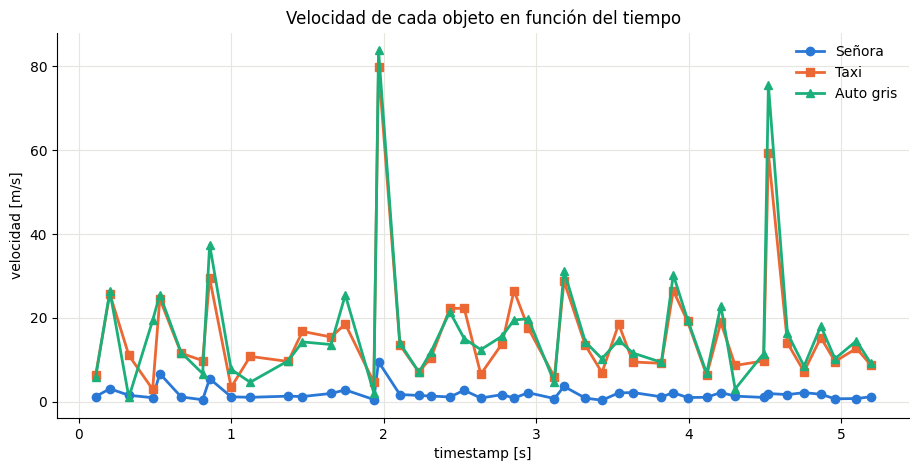

In [104]:
import matplotlib.pyplot as plt

# Grafico la velocidad de cada objeto a lo largo del tiempo
# (la primera fila es NaN porque diff() no tiene un punto anterior, matplotlib la saltea)
series = [
    ("velocidad_senora", "Señora", "#2a78d6", "o"),
    ("velocidad_taxi", "Taxi", "#eb6834", "s"),
    ("velocidad_auto_gris", "Auto gris", "#1baf7a", "^"),
]

fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, marcador in series:
    ax.plot(dataset["timestamp"], dataset[columna], color=color, linewidth=2,
            marker=marcador, markersize=6, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

mirando el grafico hay picos muy altos, fui a revisar las fotografias y los puntos entre fotos consecutivos estan bien hechos pero el timestamp es muy corto para el movimiento que podria haberse realizado en ese punto por lo que se puede sugerir que el timestamp de la foto esta mal o se grabó de manera incorrecta por lo que voy a proceder a quitarlos

In [105]:
# Saco las filas 15 y 38. Los puntos están bien, pero el timestamp de esas dos fotos no se corresponde
# con el movimiento, el timestamp de la foto esta mal o se grabó de manera incorrecta
dataset_filtrado = dataset.drop(index=[15, 38])

dataset_filtrado["X_seniora_diff"] = dataset_filtrado["X_seniora"].diff()
dataset_filtrado["Y_seniora_diff"] = dataset_filtrado["Y_seniora"].diff()
dataset_filtrado["X_taxi_diff"] = dataset_filtrado["X_taxi"].diff()
dataset_filtrado["Y_taxi_diff"] = dataset_filtrado["Y_taxi"].diff()
dataset_filtrado["X_auto_gris_diff"] = dataset_filtrado["X_auto_gris"].diff()
dataset_filtrado["Y_auto_gris_diff"] = dataset_filtrado["Y_auto_gris"].diff()
dataset_filtrado["dt"] = dataset_filtrado["timestamp"].diff()
dataset_filtrado["distancia_senora"] = np.sqrt((dataset_filtrado["X_seniora_diff"]**2) + (dataset_filtrado["Y_seniora_diff"]**2))
dataset_filtrado["velocidad_senora"] = dataset_filtrado["distancia_senora"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_taxi"] = np.sqrt((dataset_filtrado["X_taxi_diff"]**2) + (dataset_filtrado["Y_taxi_diff"]**2))
dataset_filtrado["velocidad_taxi"] = dataset_filtrado["distancia_taxi"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_auto_gris"] = np.sqrt((dataset_filtrado["X_auto_gris_diff"]**2) + (dataset_filtrado["Y_auto_gris_diff"]**2))
dataset_filtrado["velocidad_auto_gris"] = dataset_filtrado["distancia_auto_gris"] / dataset_filtrado["dt"]

dataset_filtrado[["timestamp", "dt", "velocidad_senora", "velocidad_taxi", "velocidad_auto_gris"]]

,timestamp,dt,velocidad_senora,velocidad_taxi,velocidad_auto_gris
0,0.000,NaN,NaN,NaN,NaN
1,0.110,0.110,1.198466,6.317374,5.768291
2,0.203,0.093,3.061176,25.698706,26.335856
3,0.328,0.125,1.503508,11.023905,1.000047
4,0.484,0.156,0.927866,2.929345,19.369489
5,0.531,0.047,6.671353,24.500287,25.541651
6,0.671,0.140,1.110857,11.545026,11.698150
7,0.812,0.141,0.436236,9.775062,6.683224
8,0.858,0.046,5.459675,29.419089,37.419756
9,0.999,0.141,1.139907,3.402079,7.670172


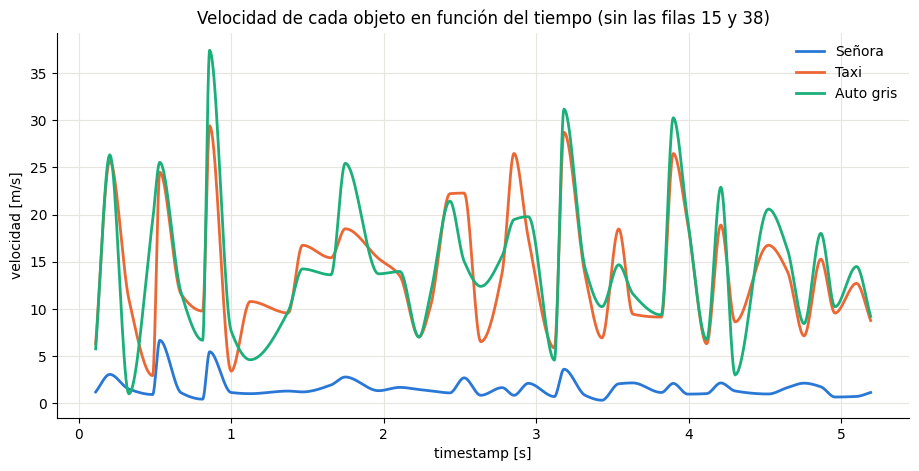

In [106]:
def curva_suave(x, y, puntos_por_tramo=20):
    # Interpolación cúbica de Hermite con las pendientes de Fritsch-Carlson, solo para dibujar:
    # la curva pasa exactamente por todos los puntos y entre dos puntos no se pasa de largo,
    # así no inventa picos ni velocidades negativas que no están en los datos
    n = len(x)
    h = x[1:] - x[:-1]              # ancho de cada tramo
    delta = (y[1:] - y[:-1]) / h    # pendiente de la recta que une cada par de puntos

    # Pendiente de la curva en cada punto
    m = np.zeros(n)
    m[0] = delta[0]
    m[n - 1] = delta[n - 2]
    for k in range(1, n - 1):
        # Si la curva sigue subiendo (o bajando), promedio armónico ponderado de las dos rectas vecinas.
        # Si cambia de dirección (es un pico o un valle), queda pendiente 0 para no pasarse de largo
        if delta[k - 1] * delta[k] > 0:
            w1 = 2 * h[k] + h[k - 1]
            w2 = h[k] + 2 * h[k - 1]
            m[k] = (w1 + w2) / (w1 / delta[k - 1] + w2 / delta[k])

    # En cada tramo armo el polinomio cúbico que pasa por los dos puntos con esas pendientes
    s = np.arange(puntos_por_tramo) / puntos_por_tramo   # de 0 a 1 dentro del tramo
    h00 = 2 * s**3 - 3 * s**2 + 1
    h10 = s**3 - 2 * s**2 + s
    h01 = -2 * s**3 + 3 * s**2
    h11 = s**3 - s**2
    x_suave = []
    y_suave = []
    for k in range(n - 1):
        x_suave.append(x[k] + s * h[k])
        y_suave.append(h00 * y[k] + h10 * h[k] * m[k] + h01 * y[k + 1] + h11 * h[k] * m[k + 1])
    x_suave.append(np.array([x[n - 1]]))
    y_suave.append(np.array([y[n - 1]]))
    return np.hstack(x_suave), np.hstack(y_suave)


# Mismo gráfico que antes, pero con el dataset sin las filas 15 y 38 y con curvas suaves.
# Los datos no cambian: la curva pasa exactamente por cada valor calculado
puntos_por_tramo = 20
fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, _ in series:   # el marcador de series no lo uso en este gráfico
    # Salteo la primera fila porque la velocidad es NaN (no tiene punto anterior)
    t = np.array(dataset_filtrado["timestamp"])[1:]
    velocidad = np.array(dataset_filtrado[columna])[1:]
    t_suave, velocidad_suave = curva_suave(t, velocidad, puntos_por_tramo)
    ax.plot(t_suave, velocidad_suave, color=color, linewidth=2, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo (sin las filas 15 y 38)")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()